In [1]:
import matplotlib.pyplot as plt
import numpy as np

In [2]:
data_filepath = "Static data/data_GAP_R2_M256.txt"
data = np.loadtxt(data_filepath)
m = np.unique(data[:, 0])
g = np.unique(data[:, 1])
gap = data[:, -1]

In [3]:
import matplotlib
from matplotlib import cm
from matplotlib.colors import LinearSegmentedColormap, ListedColormap

def cmap_map(function, cmap):
    """ Applies function (which should operate on vectors of shape 3: [r, g, b]), on colormap cmap.
    This routine will break any discontinuous points in a colormap.
    """
    cdict = cmap._segmentdata
    step_dict = {}
    # Firt get the list of points where the segments start or end
    for key in ('red', 'green', 'blue'):
        step_dict[key] = list(map(lambda x: x[0], cdict[key]))
    step_list = sum(step_dict.values(), [])
    step_list = np.array(list(set(step_list)))
    # Then compute the LUT, and apply the function to the LUT
    reduced_cmap = lambda step : np.array(cmap(step)[0:3])
    old_LUT = np.array(list(map(reduced_cmap, step_list)))
    new_LUT = np.array(list(map(function, old_LUT)))
    # Now try to make a minimal segment definition of the new LUT
    cdict = {}
    for i, key in enumerate(['red','green','blue']):
        this_cdict = {}
        for j, step in enumerate(step_list):
            if step in step_dict[key]:
                this_cdict[step] = new_LUT[j, i]
            elif new_LUT[j,i] != old_LUT[j, i]:
                this_cdict[step] = new_LUT[j, i]
        colorvector = list(map(lambda x: x + (x[1], ), this_cdict.items()))
        colorvector.sort()
        cdict[key] = colorvector

    return matplotlib.colors.LinearSegmentedColormap('colormap',cdict,1024)

def pastelize_cmap(cmap, alpha=0.5, N=256):
    # Get the original colormap
    # base = cm.get_cmap(cmap_name, N)
    base = cmap
    # Blend each color with white
    colors = base(np.linspace(0, 1, N))
    white = np.ones_like(colors)
    # white = np.zeros_like(colors)
    pastel_colors = colors * (1 - alpha) + white * alpha
    # Preserve alpha channel if present
    pastel_colors[:, 3] = colors[:, 3]
    return ListedColormap(pastel_colors)

def truncate_colormap(cmap, minval=0.0, maxval=1.0, n=256):
    new_cmap = LinearSegmentedColormap.from_list(
        f'trunc({cmap.name},{minval:.2f},{maxval:.2f})',
        cmap(np.linspace(minval, maxval, n))
    )
    return new_cmap

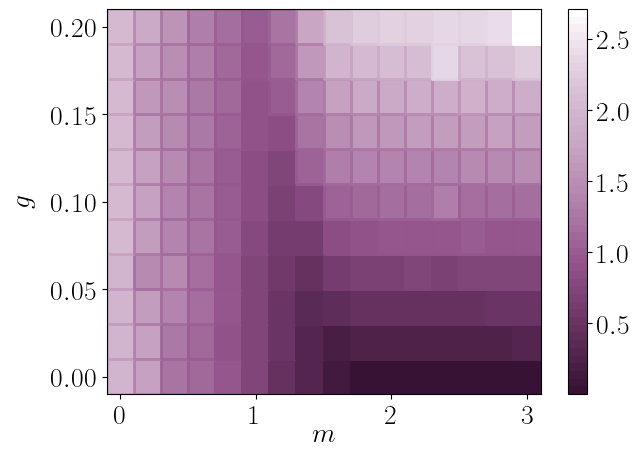

In [12]:
M, G = np.meshgrid(m, g)
gap = gap.reshape(M.shape)

plt.rc("text", usetex=True)
plt.rc("font", family="serif", size=20)

import seaborn as sns
#cmap = plt.get_cmap("rainbow_r")
cmap = sns.color_palette("magma", as_cmap=True)
colors = ["#381234", "#93528B", "#B484AEB2", "#FFFFFF"] # first color is black, last is red
cmap = LinearSegmentedColormap.from_list(
        "Custom", colors, N=50)

#cmap = pastelize_cmap(cmap, 0.05)

plt.figure(figsize=(7, 5))
plt.pcolormesh(M, G, gap, edgecolors="face", cmap=cmap)
plt.xlabel(r"$m$", labelpad=-5)
plt.ylabel(r"$g$", labelpad=12)
cbar = plt.colorbar()
plt.savefig("gap_data.svg", facecolor="none")